# Support Vector Machines (SVM)

In [1]:
%pip install -q numpy pandas matplotlib scikit-learn

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs, make_circles, make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

np.random.seed(0)

### Helpers
- `split` turns labels into $\{-1, +1\}$, makes a train/test split and standardises the features (SVMs need scaled features; see Section 4.2).
- `plot_svm` is used in every section. It draws:
  - the decision boundary $f(x) = 0$ (solid line) and the margins $f(x) = \pm 1$ (dashed lines)
  - training points as **circles**, test points as **triangles** (blue = $+1$, red = $-1$)
  - **support vectors** with a black ring, and bounded support vectors (Section 3) with an orange ring
  - misclassified test points with a black **×**

In [3]:
def split(X, y):
    y = np.where(y == 0, -1, 1)
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
    scaler = StandardScaler().fit(X_tr)
    return scaler.transform(X_tr), scaler.transform(X_te), y_tr, y_te

def accuracy(f, X, y):
    return np.mean(np.sign(f(X)) == y)

def plot_svm(f, X_tr, y_tr, X_te, y_te, sv=None, bounded=None, title=""):
    # f(X) returns the decision value for each row; sv and bounded are boolean masks over X_tr
    pts = np.vstack([X_tr, X_te])
    lo, hi = pts.min(0) - 0.5, pts.max(0) + 0.5
    xx, yy = np.meshgrid(np.linspace(lo[0], hi[0], 300), np.linspace(lo[1], hi[1], 300))
    Z = f(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, np.sign(Z), levels=[-1.5, 0, 1.5], colors=["tab:red", "tab:blue"], alpha=0.1)
    plt.contour(xx, yy, Z, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])

    for label, color in [(1, "tab:blue"), (-1, "tab:red")]:
        plt.scatter(*X_tr[y_tr == label].T, c=color, s=25, label=f"train y={label:+d}")
        plt.scatter(*X_te[y_te == label].T, c=color, s=60, marker="^", edgecolors="k", label=f"test y={label:+d}")
    if sv is not None:
        plt.scatter(*X_tr[sv].T, s=180, facecolors="none", edgecolors="k", linewidths=1.5, label="support vector")
    if bounded is not None and bounded.any():
        plt.scatter(*X_tr[bounded].T, s=180, facecolors="none", edgecolors="orange", linewidths=1.5, label="bounded SV (α = C)")
    wrong = np.sign(f(X_te)) != y_te
    if wrong.any():
        plt.scatter(*X_te[wrong].T, s=120, marker="x", c="k", label="misclassified test")

    plt.title(title)
    plt.legend(fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

---
## 1. Hard-margin SVM

### 1.1 Idea
Many lines can separate two classes. SVM picks the one with the **largest margin**: the widest gap between the line and the closest points of each class. A wide margin leaves more room for error on new points.

Labels are $y_i \in \{-1, +1\}$ and the classifier is

$$f(x) = w^Tx + b, \qquad \hat y = \text{sign}\big(f(x)\big)$$

### 1.2 The margin
Scale $w$ and $b$ so that the closest points satisfy $w^Tx + b = \pm 1$. These two lines are the **margin boundaries**, and the distance between them is

$$\text{margin} = \frac{2}{\lVert w\rVert}$$

Every point must be on its correct side, on or outside the margin:

$$y_i\,(w^Tx_i + b) \ge 1 \qquad \text{for all } i$$

### 1.3 The primal problem
Maximising $\frac{2}{\lVert w\rVert}$ is the same as minimising $\lVert w\rVert$. We minimise $\frac12\lVert w\rVert^2$ instead: it has the same minimiser, no square root, and its derivative is just $w$.

$$\min_{w,\,b}\ \frac12\lVert w\rVert^2 \qquad \text{s.t.} \qquad y_i\,(w^Tx_i + b) \ge 1$$

### 1.4 Absorbing $b$
Append a constant $1$ to every point: $\tilde x = [x,\ 1]$ and $\tilde w = [w,\ b]$. Then $w^Tx + b = \tilde w^T\tilde x$, so there is no separate $b$:

$$\min_{\tilde w}\ \frac12\lVert \tilde w\rVert^2 \qquad \text{s.t.} \qquad y_i\,\tilde w^T\tilde x_i \ge 1$$

Side effect: $b$ is now penalised too, so the answer can differ slightly from scikit-learn's.

### 1.5 Lagrangian and dual
Add one multiplier $\alpha_i \ge 0$ for each constraint:

$$L(\tilde w, \alpha) = \frac12\lVert \tilde w\rVert^2 - \sum_i \alpha_i\big(y_i\,\tilde w^T\tilde x_i - 1\big)$$

Setting $\dfrac{\partial L}{\partial \tilde w} = 0$ gives

$$\tilde w = \sum_i \alpha_i y_i \tilde x_i$$

Substituting this back gives the **dual**, which depends only on $\alpha$:

$$\max_{\alpha}\ \sum_i \alpha_i - \frac12\sum_i\sum_j \alpha_i\alpha_j\,y_iy_j\,\tilde x_i^T\tilde x_j \qquad \text{s.t.} \qquad \alpha_i \ge 0$$

where $\tilde x_i^T\tilde x_j = x_i^Tx_j + 1$.

> With a separate $b$, $\frac{\partial L}{\partial b} = 0$ would add the extra constraint $\sum_i \alpha_i y_i = 0$. Absorbing $b$ removes it, which keeps gradient ascent simple.

### 1.6 Finding $\alpha$ with gradient ascent
Why not just set $\frac{\partial L}{\partial \alpha_i} = 0$? Most points end up with $\alpha_i = 0$, on the edge of the allowed region $\alpha_i \ge 0$, where the derivative is **not** zero. So we climb step by step and clip.

Let $K_{ij} = \tilde x_i^T\tilde x_j$ and $Q_{ij} = y_iy_jK_{ij}$. Then

$$\frac{\partial L}{\partial \alpha_i} = 1 - y_i\sum_j \alpha_j y_j K_{ij} \qquad\Longrightarrow\qquad \nabla_\alpha L = \mathbf{1} - Q\alpha$$

Repeat until convergence:

$$\alpha \leftarrow \alpha + \eta\,(\mathbf{1} - Q\alpha), \qquad \alpha \leftarrow \max(\alpha,\ 0)$$

A safe step size is $\eta = 1/\lambda_{\max}(Q)$, one over the largest eigenvalue of $Q$.

Once we have $\alpha$, the last entry of $\tilde w$ gives $b$:

$$w = \sum_i \alpha_i y_i x_i, \qquad b = \sum_i \alpha_i y_i$$

In [4]:
X_tr, X_te, y_tr, y_te = split(*make_blobs(n_samples=80, centers=2, cluster_std=1.0, random_state=6))

def fit_hard_svm(X, y, epochs=20000):
    K = X @ X.T + 1                        # x_i·x_j + 1   (the +1 is the absorbed b)
    Q = np.outer(y, y) * K                 # Q_ij = y_i y_j K_ij
    lr = 1 / np.linalg.eigvalsh(Q).max()   # safe step size
    alpha = np.zeros(len(y))
    for _ in range(epochs):
        alpha += lr * (1 - Q @ alpha)      # gradient ascent step
        alpha = np.maximum(alpha, 0)       # keep α ≥ 0
    return alpha

alpha = fit_hard_svm(X_tr, y_tr)
w = (alpha * y_tr) @ X_tr
b = (alpha * y_tr).sum()
f = lambda X: X @ w + b

print("w =", w.round(3), "  b =", round(b, 3))
print("train acc:", accuracy(f, X_tr, y_tr), "  test acc:", accuracy(f, X_te, y_te))

w = [-0.379 -2.03 ]   b = -0.009
train acc: 1.0   test acc: 1.0


### 1.7 Support vectors
Most $\alpha_i$ come out as $0$. The points with $\alpha_i > 0$ are the **support vectors**. They lie exactly on the margin, $y_i f(x_i) = 1$, and they alone define $w$ and $b$.

Gradient ascent gives tiny numbers instead of exact zeros, so we treat $\alpha_i > 10^{-4}$ as "greater than zero".

support vectors: 3 out of 60 training points
their α        : [1.186 2.137 0.942]
their y·f(x)   : [1. 1. 1.]  (≈ 1, on the margin)


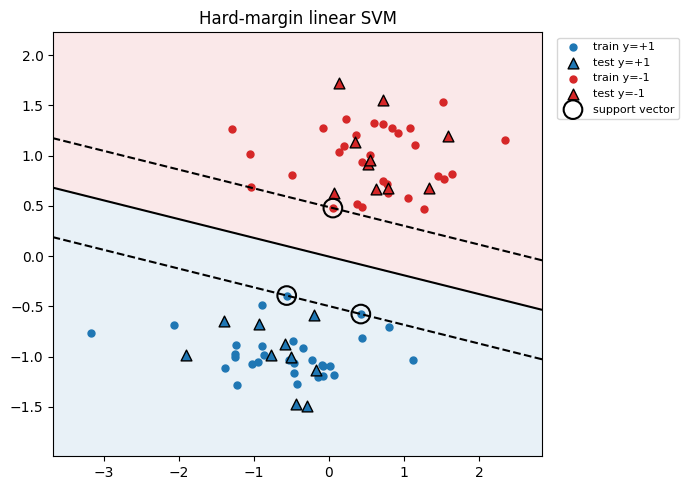

In [5]:
sv = alpha > 1e-4
print("support vectors:", sv.sum(), "out of", len(y_tr), "training points")
print("their α        :", alpha[sv].round(3))
print("their y·f(x)   :", (y_tr[sv] * f(X_tr[sv])).round(3), " (≈ 1, on the margin)")

plot_svm(f, X_tr, y_tr, X_te, y_te, sv=sv, title="Hard-margin linear SVM")

**Only the support vectors matter.** Remove a non-support vector and refit: nothing changes. Remove a support vector: the boundary moves.

In [6]:
def refit_without(i):
    keep = np.arange(len(y_tr)) != i
    a = fit_hard_svm(X_tr[keep], y_tr[keep])
    return ((a * y_tr[keep]) @ X_tr[keep]).round(3), round((a * y_tr[keep]).sum(), 3)

print("all points        w, b =", w.round(3), round(b, 3))
print("drop a non-SV  -> w, b =", *refit_without(np.where(~sv)[0][0]))
print("drop an SV     -> w, b =", *refit_without(np.where(sv)[0][0]))

all points        w, b = [-0.379 -2.03 ] -0.009
drop a non-SV  -> w, b = [-0.379 -2.03 ] -0.009
drop an SV     -> w, b = [-0.127 -1.941] -0.065


---
## 2. Kernels

### 2.1 When a line is not enough
Here one class sits inside a ring of the other. No straight line can separate them.

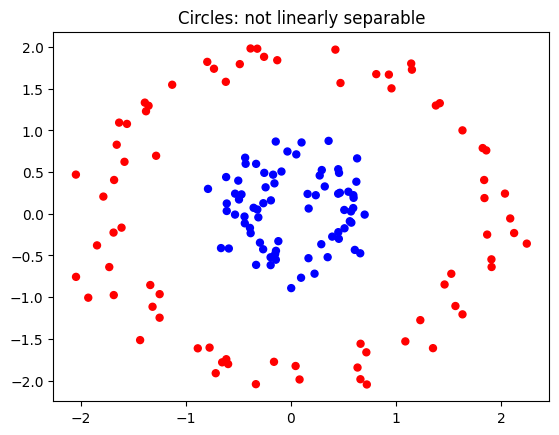

In [7]:
X_tr, X_te, y_tr, y_te = split(*make_circles(n_samples=200, factor=0.3, noise=0.08, random_state=0))

plt.scatter(*X_tr.T, c=y_tr, cmap="bwr_r", s=25)
plt.title("Circles: not linearly separable")
plt.show()

### 2.2 Map to a higher dimension
Add one feature, the squared distance from the origin:

$$\phi(x) = [\,x_1,\ x_2,\ x_1^2 + x_2^2\,]$$

In 3D the inner points sit low and the ring sits high, so a flat **plane** separates them. A plane in $\phi$-space is a circle back in 2D.

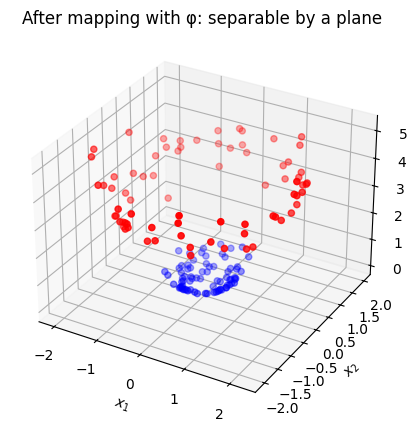

In [8]:
z = (X_tr ** 2).sum(1)

ax = plt.figure(figsize=(6, 5)).add_subplot(projection="3d")
ax.scatter(X_tr[:, 0], X_tr[:, 1], z, c=y_tr, cmap="bwr_r", s=20)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_zlabel("$x_1^2 + x_2^2$")
ax.set_title("After mapping with φ: separable by a plane")
plt.show()

### 2.3 The kernel trick
The dual uses the data **only through dot products**. After mapping, $x_i^Tx_j$ becomes $\phi(x_i)^T\phi(x_j)$.

The problem is that $\phi$ can be huge:
- All polynomial features up to degree $d$ in $p$ dimensions number $\binom{p+d}{d}$. With $p = 100$ and $d = 5$ that is about **96 million** features.
- For the RBF kernel, $\phi$ is **infinite**-dimensional.

Building $\phi(x)$ first and then taking dot products is too expensive. A **kernel** computes the same dot product straight from the original $x$, without ever building $\phi$:

$$K(x_i, x_j) = \phi(x_i)^T\phi(x_j)$$

**Example** in 2D: $(x^Tz)^2 = x_1^2z_1^2 + 2x_1x_2z_1z_2 + x_2^2z_2^2 = \phi(x)^T\phi(z)$ with $\phi(x) = [x_1^2,\ \sqrt2\,x_1x_2,\ x_2^2]$. One 2D dot product, squared, replaces building 3D features.

| Kernel | $K(x, z)$ | Boundary |
|---|---|---|
| Linear | $x^Tz$ | straight line (Section 1) |
| Polynomial | $(x^Tz + c)^d$ | degree-$d$ curve |
| RBF (Gaussian) | $\exp\!\big(-\gamma\lVert x - z\rVert^2\big)$ | any smooth shape |

I've replaced that paragraph in Section 2.3 of [SVM.ipynb](../SVM/SVM.ipynb). It now reads:

---

The RBF kernel measures how similar two points are: $K(x, z) = 1$ when $x = z$, and it falls towards $0$ as the points move apart. $\gamma$ controls how fast it falls, so each training point only influences points within a distance of about $1/\sqrt{\gamma}$.

The prediction is $f(x) = \sum_{i \in SV} \alpha_i y_i \big(K(x_i, x) + 1\big)$ (derived in 2.4 below), so every support vector adds a "bump" centred on itself, pushing nearby points towards its class. The decision boundary is where the bumps of the two classes cancel out.

| | Small $\gamma$ | Large $\gamma$ |
|---|---|---|
| Bump width | wide: each point influences a large area | narrow: each point influences only its close neighbours |
| Decision boundary | smooth and gently curved (close to a straight line as $\gamma \to 0$) | wiggly; wraps tightly around individual points and forms small islands |
| Support vectors | few | many, often most of the training points |
| Risk | underfitting | overfitting |

---

### 2.4 Kernel SVM
Everything from Section 1 stays the same; only $K$ changes (the $+1$ is still the absorbed $b$):

$$K_{ij} = K(x_i, x_j) + 1$$

We can no longer compute $w$, because it lives in $\phi$-space. We don't need it: substitute $w = \sum_i \alpha_i y_i \phi(x_i)$ into $f$:

$$f(x) = \sum_{i \in \text{SV}} \alpha_i y_i \big(K(x_i, x) + 1\big)$$

So a kernel SVM must **keep its support vectors** to make predictions.

In [9]:
def linear_kernel(A, B):
    return A @ B.T

def poly_kernel(A, B, degree=3, c=1):
    return (A @ B.T + c) ** degree

def rbf_kernel(A, B, gamma=1.0):
    sq_dist = (A ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None, :] - 2 * A @ B.T   # ||a - b||²
    return np.exp(-gamma * sq_dist)

def fit_kernel_svm(X, y, kernel, epochs=20000):
    K = kernel(X, X) + 1                   # the only change from Section 1
    Q = np.outer(y, y) * K
    lr = 1 / np.linalg.eigvalsh(Q).max()
    alpha = np.zeros(len(y))
    for _ in range(epochs):
        alpha += lr * (1 - Q @ alpha)
        alpha = np.maximum(alpha, 0)
    return alpha

def make_f(X, y, alpha, kernel):
    sv = alpha > 1e-4                      # keep only the support vectors
    return lambda X_new: (alpha[sv] * y[sv]) @ (kernel(X[sv], X_new) + 1)

Polynomial (d=2): 6 SVs, train acc 1.00, test acc 1.00


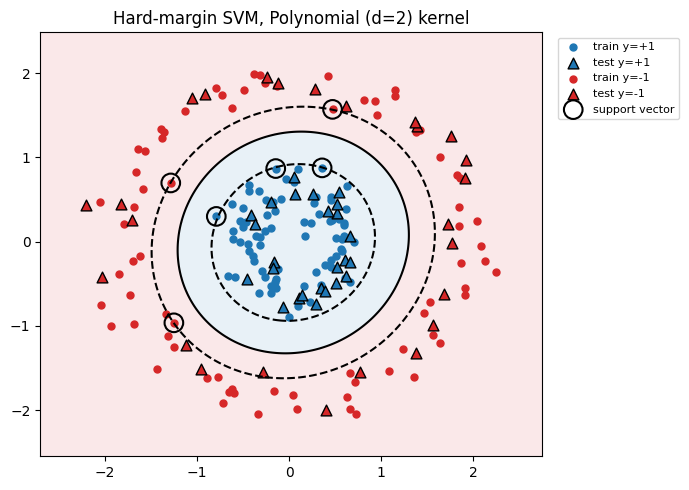

RBF (γ=1): 17 SVs, train acc 1.00, test acc 1.00


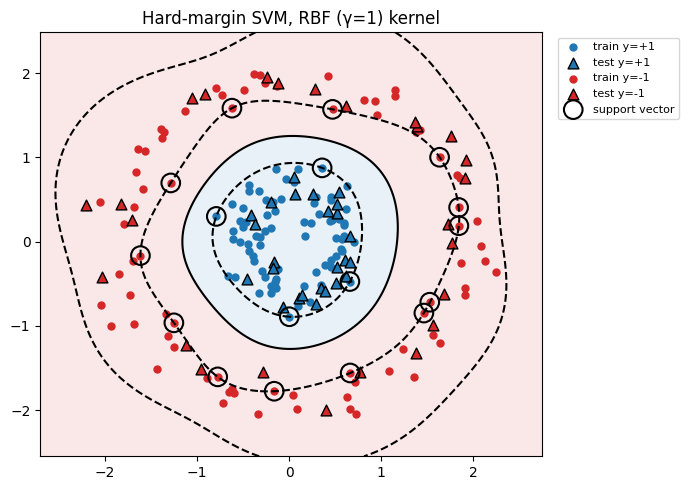

In [10]:
kernels = {
    "Polynomial (d=2)": lambda A, B: poly_kernel(A, B, degree=2),
    "RBF (γ=1)":        lambda A, B: rbf_kernel(A, B, gamma=1),
}

for name, kernel in kernels.items():
    alpha = fit_kernel_svm(X_tr, y_tr, kernel)
    f = make_f(X_tr, y_tr, alpha, kernel)
    print(f"{name}: {(alpha > 1e-4).sum()} SVs, train acc {accuracy(f, X_tr, y_tr):.2f}, test acc {accuracy(f, X_te, y_te):.2f}")
    plot_svm(f, X_tr, y_tr, X_te, y_te, sv=alpha > 1e-4, title=f"Hard-margin SVM, {name} kernel")

### 2.5 Problem: hard margin + RBF overfits
With RBF, a hard-margin SVM can separate **any** training set perfectly, noise included. On noisy moons, a large $\gamma$ gives 100% training accuracy, but the boundary wraps around noisy points and test accuracy drops.

train acc 1.00, test acc 0.84, SVs 83 / 150


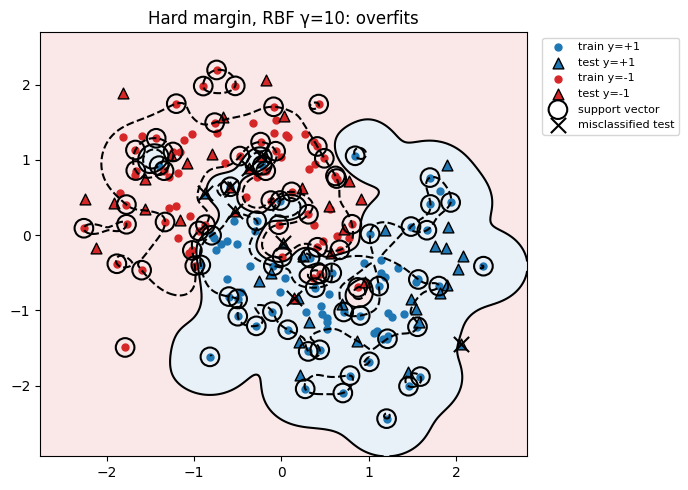

In [11]:
X_tr, X_te, y_tr, y_te = split(*make_moons(n_samples=200, noise=0.3, random_state=0))

kernel = lambda A, B: rbf_kernel(A, B, gamma=10)
alpha = fit_kernel_svm(X_tr, y_tr, kernel)
f = make_f(X_tr, y_tr, alpha, kernel)

print(f"train acc {accuracy(f, X_tr, y_tr):.2f}, test acc {accuracy(f, X_te, y_te):.2f}, SVs {(alpha > 1e-4).sum()} / {len(y_tr)}")
plot_svm(f, X_tr, y_tr, X_te, y_te, sv=alpha > 1e-4, title="Hard margin, RBF γ=10: overfits")

---
## 3. Soft margin

### 3.1 Why
Hard margin demands that **every** training point be on the correct side, outside the margin. That causes two problems:
1. **Overfitting:** with kernels, the boundary bends around every noisy point (Section 2.5).
2. **No solution:** if the classes overlap, no boundary satisfies all the constraints, and the $\alpha$'s grow forever.

You can see problem 2 below: on overlapping data the largest $\alpha$ keeps growing the longer we train.

In [12]:
X_tr, X_te, y_tr, y_te = split(*make_blobs(n_samples=100, centers=2, cluster_std=2.0, random_state=6))

for epochs in [1000, 10000, 50000]:
    alpha = fit_hard_svm(X_tr, y_tr, epochs=epochs)
    print(f"epochs = {epochs:>5}:  max α = {alpha.max():.1f}")

epochs =  1000:  max α = 10.0
epochs = 10000:  max α = 81.0
epochs = 50000:  max α = 273.8


### 3.2 Slack variables
Give each point a **slack** $\xi_i \ge 0$ that lets it break the margin, and charge $C$ per unit of slack ($b$ is still absorbed in $w$):

$$\min_{w,\,\xi}\ \frac12\lVert w\rVert^2 + C\sum_i \xi_i \qquad \text{s.t.} \qquad y_i\,w^Tx_i \ge 1 - \xi_i, \quad \xi_i \ge 0$$

| $\xi_i$ | Point |
|---|---|
| $0$ | on or outside the margin, correct side |
| $0 < \xi_i \le 1$ | inside the margin, still correctly classified |
| $> 1$ | misclassified |

- **Large $C$**: violations are expensive, so the margin is narrow and the model fits the training data tightly (risk of **overfitting**). $C \to \infty$ is the hard margin.
- **Small $C$**: violations are cheap, so the margin is wide and the boundary smooth (risk of **underfitting**).

**Hinge-loss view:** at the optimum $\xi_i = \max\big(0,\ 1 - y_if(x_i)\big)$, so the same problem is

$$\min_w\ \frac12\lVert w\rVert^2 + C\sum_i \max\big(0,\ 1 - y_i f(x_i)\big)$$

### 3.3 What changes in the dual
Add multipliers $\alpha_i \ge 0$ for the margin constraints and $\beta_i \ge 0$ for $\xi_i \ge 0$:

$$L = \frac12\lVert w\rVert^2 + C\sum_i \xi_i - \sum_i \alpha_i\big(y_i\,w^Tx_i - 1 + \xi_i\big) - \sum_i \beta_i\xi_i$$

$$\frac{\partial L}{\partial \xi_i} = C - \alpha_i - \beta_i = 0 \quad\Longrightarrow\quad \beta_i = C - \alpha_i \ge 0 \quad\Longrightarrow\quad \alpha_i \le C$$

The $\xi$ terms cancel out, so the dual is **exactly the same as before**, with one extra limit:

$$0 \le \alpha_i \le C$$

In code, we clip $\alpha$ to $[0, C]$ instead of $[0, \infty)$. **One line changes.**

### 3.4 Two kinds of support vectors

| $\alpha_i$ | Point | Plot |
|---|---|---|
| $0$ | outside the margin, not a support vector | no ring |
| $0 < \alpha_i < C$ | exactly on the margin, $y_if(x_i) = 1$ | black ring |
| $\alpha_i = C$ | inside the margin or misclassified, $y_if(x_i) < 1$ | orange ring (**bounded**) |

In [13]:
def fit_soft_svm(X, y, kernel, C=1.0, epochs=20000):
    K = kernel(X, X) + 1
    Q = np.outer(y, y) * K
    lr = 1 / np.linalg.eigvalsh(Q).max()
    alpha = np.zeros(len(y))
    for _ in range(epochs):
        alpha += lr * (1 - Q @ alpha)
        alpha = np.clip(alpha, 0, C)       # the only change: 0 ≤ α ≤ C
    return alpha

def plot_soft(alpha, kernel, C, title):
    f = make_f(X_tr, y_tr, alpha, kernel)
    sv, bounded = alpha > 1e-4, np.isclose(alpha, C)
    print(f"{title}: train acc {accuracy(f, X_tr, y_tr):.2f}, test acc {accuracy(f, X_te, y_te):.2f}, "
          f"SVs {sv.sum()} ({bounded.sum()} bounded)")
    plot_svm(f, X_tr, y_tr, X_te, y_te, sv=sv, bounded=bounded, title=title)

**Overlapping blobs, linear kernel.** Hard margin had no solution here; soft margin works fine.

Soft margin, linear, C=1: train acc 0.99, test acc 0.96, SVs 16 (13 bounded)


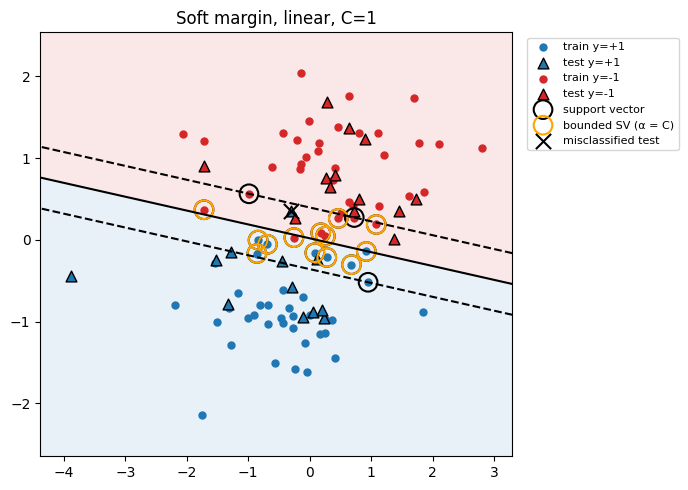

In [14]:
alpha = fit_soft_svm(X_tr, y_tr, linear_kernel, C=1)
plot_soft(alpha, linear_kernel, C=1, title="Soft margin, linear, C=1")

**Noisy moons, RBF $\gamma = 3$.** The same data that overfit in Section 2.5. Small $C$ gives a wide margin and a smooth boundary. Very large $C$ behaves like the hard margin again: training accuracy goes up, test accuracy goes down.

Soft margin, RBF γ=3, C=0.1: train acc 0.93, test acc 0.90, SVs 144 (138 bounded)


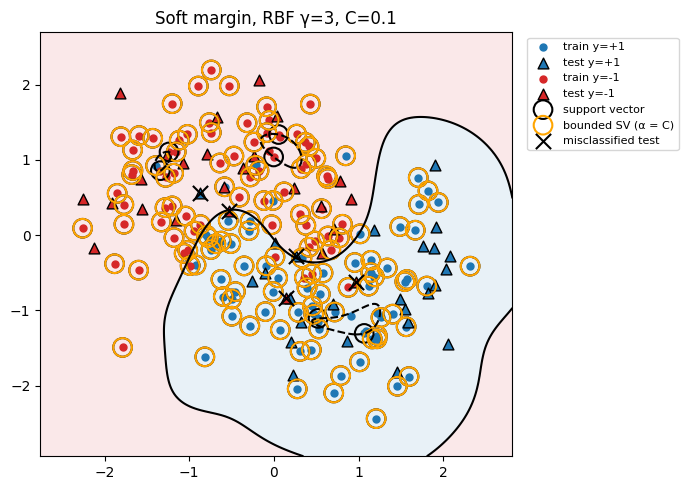

Soft margin, RBF γ=3, C=1: train acc 0.93, test acc 0.90, SVs 78 (31 bounded)


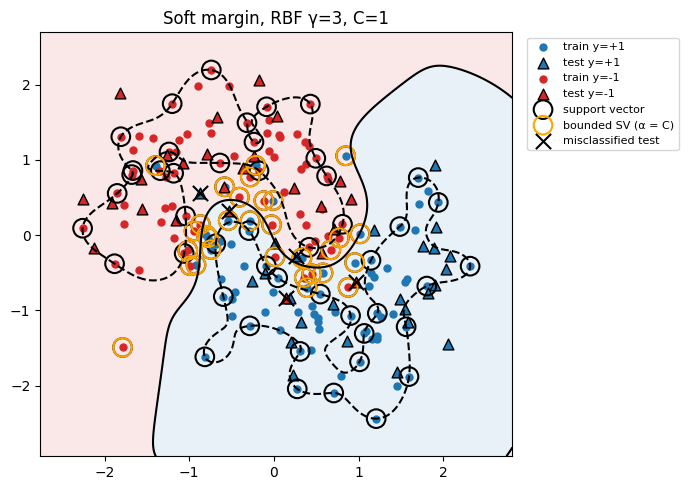

Soft margin, RBF γ=3, C=1000: train acc 0.97, test acc 0.88, SVs 55 (0 bounded)


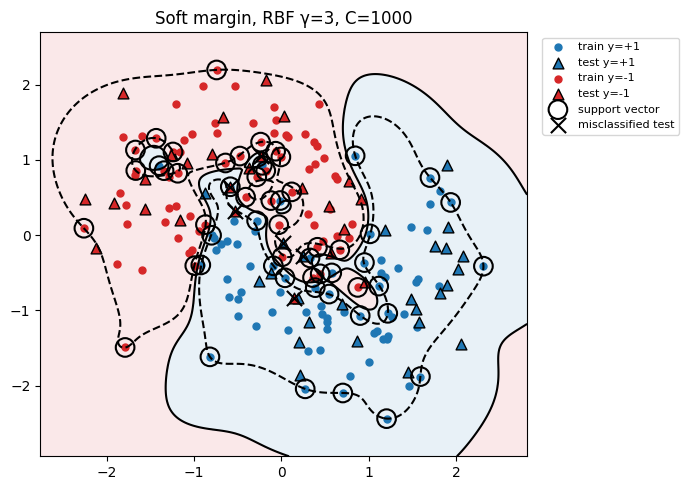

In [15]:
X_tr, X_te, y_tr, y_te = split(*make_moons(n_samples=200, noise=0.3, random_state=0))
kernel = lambda A, B: rbf_kernel(A, B, gamma=3)

for C in [0.1, 1, 1000]:
    alpha = fit_soft_svm(X_tr, y_tr, kernel, C=C)
    plot_soft(alpha, kernel, C, title=f"Soft margin, RBF γ=3, C={C}")

### 3.5 Choosing $C$ and $\gamma$ together
Both control flexibility: **large $C$ and large $\gamma$ overfit; small $C$ and small $\gamma$ underfit.** Here is test accuracy over a small grid:

In [16]:
Cs, gammas = [0.1, 1, 10, 100], [0.1, 1, 10]

print("test acc".ljust(10) + "".join(f"γ={g:<7}" for g in gammas))
for C in Cs:
    row = []
    for g in gammas:
        kernel = lambda A, B: rbf_kernel(A, B, gamma=g)
        f = make_f(X_tr, y_tr, fit_soft_svm(X_tr, y_tr, kernel, C=C), kernel)
        row.append(f"{accuracy(f, X_te, y_te):<9.2f}")
    print(f"C={C:<8}" + "".join(row))

test acc  γ=0.1    γ=1      γ=10     
C=0.1     0.88     0.92     0.88     
C=1       0.88     0.90     0.88     
C=10      0.90     0.88     0.88     
C=100     0.92     0.86     0.84     


---
## 4. SVMs in scikit-learn
`sklearn.svm.SVC` solves the same dual with **SMO**, which is much faster than gradient ascent, and keeps $b$ separate.

| Ours | scikit-learn |
|---|---|
| kernel function | `kernel="linear"`, `"poly"` (`degree`, `coef0`), `"rbf"` (`gamma`) |
| `C` | `C` |
| support vectors ($\alpha_i > 0$) | `support_` (indices), `support_vectors_`, `n_support_` (per class) |
| $\alpha_i y_i$ | `dual_coef_` |
| $w$, $b$ | `coef_` (linear kernel only), `intercept_` |

### 4.1 Same model, compared with ours

ours   : SVs 63   test acc 0.9
sklearn: SVs 63   test acc 0.9
support vectors in common: 63


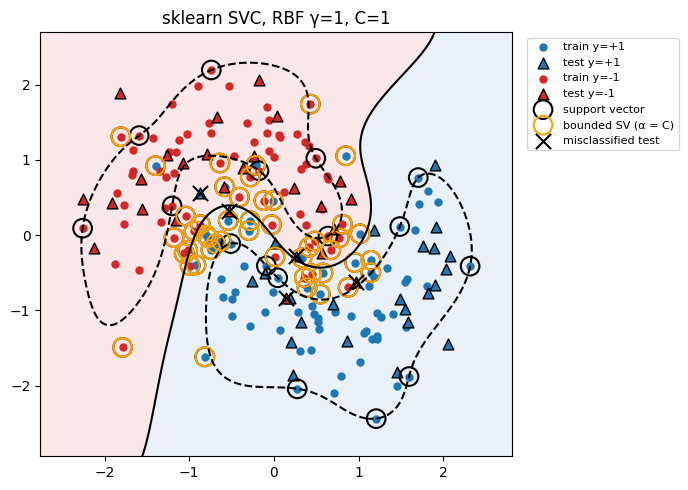

In [17]:
from sklearn.svm import SVC

X_tr, X_te, y_tr, y_te = split(*make_moons(n_samples=200, noise=0.3, random_state=0))

kernel = lambda A, B: rbf_kernel(A, B, gamma=1)
alpha = fit_soft_svm(X_tr, y_tr, kernel, C=1)
clf = SVC(kernel="rbf", gamma=1, C=1).fit(X_tr, y_tr)

ours, theirs = set(np.where(alpha > 1e-4)[0]), set(clf.support_)
print("ours   : SVs", len(ours), "  test acc", accuracy(make_f(X_tr, y_tr, alpha, kernel), X_te, y_te))
print("sklearn: SVs", len(theirs), "  test acc", clf.score(X_te, y_te))
print("support vectors in common:", len(ours & theirs))

sv = np.isin(np.arange(len(y_tr)), clf.support_)
bounded = np.zeros(len(y_tr), bool)
bounded[clf.support_] = np.isclose(np.abs(clf.dual_coef_[0]), 1)   # |α_i y_i| = C
plot_svm(clf.decision_function, X_tr, y_tr, X_te, y_te, sv=sv, bounded=bounded, title="sklearn SVC, RBF γ=1, C=1")

### 4.2 Always scale the features
SVMs use dot products and distances, so a feature with a large range dominates. Put a `StandardScaler` in a `Pipeline`, so the test data is scaled with the training statistics.

In [18]:
from sklearn.pipeline import make_pipeline

X_big_tr, X_big_te = X_tr * [1, 100], X_te * [1, 100]   # second feature now 100× larger

print("without scaling:", SVC().fit(X_big_tr, y_tr).score(X_big_te, y_te))
print("with scaling   :", make_pipeline(StandardScaler(), SVC()).fit(X_big_tr, y_tr).score(X_big_te, y_te))

without scaling: 0.82
with scaling   : 0.92


### 4.3 Tuning $C$ and $\gamma$ with `GridSearchCV`
Instead of picking by hand (Section 3.5), use cross-validation on the training set only.

In [19]:
from sklearn.model_selection import GridSearchCV

pipe = make_pipeline(StandardScaler(), SVC(kernel="rbf"))
grid = {"svc__C": [0.1, 1, 10, 100], "svc__gamma": [0.01, 0.1, 1, 10]}

search = GridSearchCV(pipe, grid, cv=5, scoring="accuracy").fit(X_tr, y_tr)
print("best params:", search.best_params_)
print("CV acc     :", round(search.best_score_, 3))
print("test acc   :", search.score(X_te, y_te))

best params: {'svc__C': 1, 'svc__gamma': 1}
CV acc     : 0.907
test acc   : 0.9


### 4.4 `LinearSVC` for large datasets
`SVC` stores an $n \times n$ kernel matrix, so training slows down a lot as $n$ grows. For a **linear** boundary, `LinearSVC` solves the primal directly and handles hundreds of thousands of points. Raise `max_iter` if you see a `ConvergenceWarning`.

In [20]:
import time
from sklearn.svm import LinearSVC

X_l, y_l = make_blobs(n_samples=200_000, centers=2, cluster_std=3.0, random_state=0)
start = time.time()
lin = make_pipeline(StandardScaler(), LinearSVC(C=1, max_iter=5000)).fit(X_l, y_l)
print(f"LinearSVC on 200,000 points: {time.time() - start:.2f} s, train acc {lin.score(X_l, y_l):.3f}")

LinearSVC on 200,000 points: 0.25 s, train acc 0.726


### 4.5 Imbalanced classes: `class_weight="balanced"`
With few positives, the SVM can ignore them and still get high accuracy. `class_weight="balanced"` gives each class its own $C$, larger for the rare class, so its mistakes cost more.

In [21]:
from sklearn.datasets import make_classification
from sklearn.metrics import recall_score

X_i, y_i = make_classification(n_samples=1000, n_features=2, n_redundant=0, n_clusters_per_class=1,
                               weights=[0.95, 0.05], class_sep=0.8, random_state=0)
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(X_i, y_i, test_size=0.25, random_state=0, stratify=y_i)

for cw in [None, "balanced"]:
    m = SVC(kernel="rbf", class_weight=cw).fit(Xi_tr, yi_tr)
    print(f"class_weight={str(cw):<9} accuracy {m.score(Xi_te, yi_te):.3f}   recall of rare class {recall_score(yi_te, m.predict(Xi_te)):.2f}")

class_weight=None      accuracy 0.964   recall of rare class 0.43
class_weight=balanced  accuracy 0.904   recall of rare class 0.64


### 4.6 More than two classes
SVM is a binary classifier. `SVC` handles $k$ classes automatically with **one-vs-one**: it trains one SVM per pair of classes, $\frac{k(k-1)}{2}$ in all, and takes a vote. `LinearSVC` uses **one-vs-rest** instead: $k$ SVMs, each separating one class from all the others.

In [22]:
from sklearn.datasets import load_iris

X_ir, y_ir = load_iris(return_X_y=True)
Xir_tr, Xir_te, yir_tr, yir_te = train_test_split(X_ir, y_ir, test_size=0.25, random_state=0, stratify=y_ir)

iris_svm = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1)).fit(Xir_tr, yir_tr)
print("test acc            :", iris_svm.score(Xir_te, yir_te))
print("SVs per class       :", iris_svm[-1].n_support_)

test acc            : 0.9736842105263158
SVs per class       : [ 9 18 17]


### 4.7 Probabilities
SVMs output a decision value $f(x)$, not a probability. `CalibratedClassifierCV` learns a mapping from $f(x)$ to a probability using cross-validation, which enables `predict_proba`. (Older code uses `SVC(probability=True)`, which is deprecated since scikit-learn 1.9.)

In [23]:
from sklearn.calibration import CalibratedClassifierCV

prob_svm = CalibratedClassifierCV(SVC(kernel="rbf", gamma=1, C=1), ensemble=False).fit(X_tr, y_tr)
print("decision values f(x):", clf.decision_function(X_te[:5]).round(2))   # clf from 4.1, same settings
print("P(y = +1)          :", prob_svm.predict_proba(X_te[:5])[:, 1].round(2))

decision values f(x): [-1.29 -0.73 -0.81 -1.27 -0.47]
P(y = +1)          : [0.04 0.14 0.11 0.04 0.24]


### 4.8 SVM for regression: `SVR`
`SVR` fits a function with a tube of width $\varepsilon$ around it. Points inside the tube cost nothing; only points outside the tube become support vectors. `C` and the kernel work the same way as in classification.

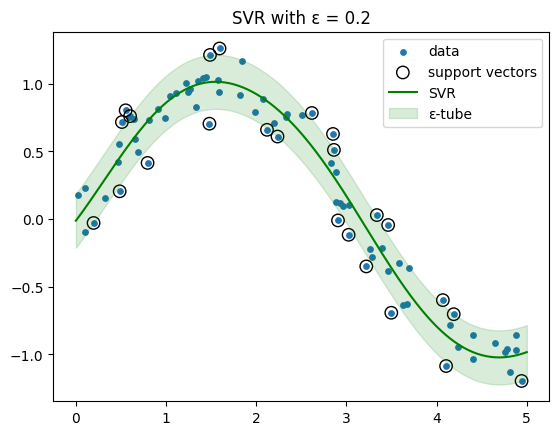

In [24]:
from sklearn.svm import SVR

x = np.sort(np.random.uniform(0, 5, 80))[:, None]
t = np.sin(x).ravel() + np.random.normal(0, 0.15, 80)

svr = SVR(kernel="rbf", C=10, epsilon=0.2).fit(x, t)
x_grid = np.linspace(0, 5, 300)[:, None]
pred = svr.predict(x_grid)

plt.scatter(x, t, s=15, label="data")
plt.scatter(x[svr.support_], t[svr.support_], s=80, facecolors="none", edgecolors="k", label="support vectors")
plt.plot(x_grid, pred, "g", label="SVR")
plt.fill_between(x_grid.ravel(), pred - 0.2, pred + 0.2, color="g", alpha=0.15, label="ε-tube")
plt.legend(); plt.title("SVR with ε = 0.2"); plt.show()

---
## Summary

| | Section 1: Hard margin | Section 2: Kernels | Section 3: Soft margin |
|---|---|---|---|
| Objective | $\min \frac12\lVert w\rVert^2$ | same, in $\phi$-space | $\min \frac12\lVert w\rVert^2 + C\sum\xi_i$ |
| $K_{ij}$ | $x_i^Tx_j + 1$ | $K(x_i, x_j) + 1$ | $K(x_i, x_j) + 1$ |
| Constraint on $\alpha$ | $\alpha_i \ge 0$ | $\alpha_i \ge 0$ | $0 \le \alpha_i \le C$ |
| Prediction | $w^Tx + b$ | $\sum_{SV}\alpha_iy_i(K(x_i,x) + 1)$ | same as Section 2 |
| Problem | linear only | overfits noise (hard margin) | tune $C$ (and $\gamma$) |

**In practice:** scale the features, start with `SVC(kernel="rbf")`, tune `C` and `gamma` with `GridSearchCV`, and switch to `LinearSVC` when the dataset is large.